# Comparison of Human Annotation vs. 3 LLM Codings

This notebook compares **Human Annotations** against **3 LLM Coding datasets** across all 4 experiments (`exp1 curv`, `exp1 noInstr`, `exp2 curv`, `exp2 noInstr`):

1. **`human`** (Ground Truth / Reference): `Curvature Open Answers.xlsx`
2. **`detailed`**: `Curvature_Open_Answers_LLM_coded_detailed.xlsx` (LLM with detailed prompt)
3. **`minimal`**: `Curvature_Open_Answers_LLM_coded_minimal.xlsx` (LLM with minimal prompt)
4. **`ai`**: `Curvature_Open_Answers_AI.xlsx` (Curvature Open Answers AI)

### Experiment Features:
- **Exp 1 (`exp1 curv`, `exp1 noInstr`)**: `smoothness`, `vertices`, `angle`, `intuition`, `globalness`, `size`
- **Exp 2 (`exp2 curv`, `exp2 noInstr`)**: `smoothness`, `vertices`, `range`, `intuition`, `globalness`, `animal-like`, `size`

### Analysis Sections:
1. **Setup & Universal Multi-Sheet Data Loader**
2. **Overall Model Performance vs. Human (Mean Agreement & Cohen's $\kappa$ Across Experiments)**
3. **Feature-Level Reliability vs. Human (Agreement % & Cohen's $\kappa$ per Experiment)**
4. **Feature Prevalence Comparison (Human vs. 3 LLMs)**
5. **Confusion Matrices (Human vs. Detailed, Minimal, AI)**
6. **Participant-Level Discrepancy Breakdown & Export**

In [1]:
# ============================================================
# 1. Setup & Data Loader Across All 4 Experiments
# ============================================================
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score, confusion_matrix, f1_score

warnings.filterwarnings('ignore')

# Resolve base directory whether notebook is run from repo root or Open_Answers/
BASE_DIR = "Open_Answers" if os.path.exists("Open_Answers/Curvature Open Answers.xlsx") else "."

FILES = {
    "human": os.path.join(BASE_DIR, "Curvature Open Answers.xlsx"),
    "detailed": os.path.join(BASE_DIR, "Curvature_Open_Answers_LLM_coded_detailed.xlsx"),
    "minimal": os.path.join(BASE_DIR, "Curvature_Open_Answers_LLM_coded_minimal.xlsx"),
    "ai": os.path.join(BASE_DIR, "Curvature_Open_Answers_AI.xlsx"),
}

LLM_MODELS = ["detailed", "minimal", "ai"]
MODEL_LABELS = {
    "human": "Human",
    "detailed": "LLM Detailed",
    "minimal": "LLM Minimal",
    "ai": "LLM AI",
}

EXPERIMENT_FEATURES = {
    "exp1 curv": ["smoothness", "vertices", "angle", "intuition", "globalness", "size"],
    "exp1 noInstr": ["smoothness", "vertices", "angle", "intuition", "globalness", "size"],
    "exp2 curv": ["smoothness", "vertices", "range", "intuition", "globalness", "animal-like", "size"],
    "exp2 noInstr": ["smoothness", "vertices", "range", "intuition", "globalness", "animal-like", "size"],
}

EXPERIMENTS = list(EXPERIMENT_FEATURES.keys())

COLUMN_ALIASES = {
    "number_of_vertices": "vertices",
    "mention_nv": "vertices",
    "mention_sm": "smoothness",
    "mention_ang": "angle",
    "animal_like": "animal-like",
}

def load_sheet(file_path, sheet_name, features):
    df = pd.read_excel(file_path, sheet_name=sheet_name, engine="openpyxl")
    df.columns = df.columns.astype(str).str.strip()
    df = df.rename(columns={k: v for k, v in COLUMN_ALIASES.items() if k in df.columns})
    
    # Standardize text column name to 'response_text'
    if "strategy_open" in df.columns:
        df["response_text"] = df["strategy_open"].fillna("").astype(str).str.strip()
    elif "open_answer" in df.columns:
        df["response_text"] = df["open_answer"].fillna("").astype(str).str.strip()
    else:
        df["response_text"] = ""
        
    df["subj_id"] = df["subj_id"].astype(str).str.strip()
    df = df[df["subj_id"].str.isdigit()].copy()
    
    for f in features:
        if f in df.columns:
            df[f] = pd.to_numeric(df[f], errors="coerce").astype("Int64")
    return df

# Load all datasets across all 4 experiments
data = {exp: {} for exp in EXPERIMENTS}
aligned_data = {}

for exp, feats in EXPERIMENT_FEATURES.items():
    for key, path in FILES.items():
        data[exp][key] = load_sheet(path, exp, feats)
        
    # Merge human with all 3 LLM models on subj_id
    h_df = data[exp]["human"][["subj_id", "response_text"] + feats].rename(
        columns={f: f"{f}_human" for f in feats}
    )
    merged = h_df.copy()
    for m in LLM_MODELS:
        m_df = data[exp][m].copy()
        extra_cols = [c for c in ["rationale", "uncertain"] if c in m_df.columns]
        rename_map = {f: f"{f}_{m}" for f in feats}
        rename_map.update({c: f"{c}_{m}" for c in extra_cols})
        m_sub = m_df[["subj_id"] + feats + extra_cols].rename(columns=rename_map)
        merged = pd.merge(merged, m_sub, on="subj_id", how="inner")
    aligned_data[exp] = merged

# Print loading summary
load_summary = []
for exp in EXPERIMENTS:
    load_summary.append({
        "Experiment": exp,
        "Human Rows": len(data[exp]["human"]),
        "Detailed Rows": len(data[exp]["detailed"]),
        "Minimal Rows": len(data[exp]["minimal"]),
        "AI Rows": len(data[exp]["ai"]),
        "Matched Subjects": len(aligned_data[exp]),
        "Features Compared": ", ".join(EXPERIMENT_FEATURES[exp]),
    })
display(pd.DataFrame(load_summary))


,Experiment,Human Rows,Detailed Rows,Minimal Rows,AI Rows,Matched Subjects,Features Compared
0,exp1 curv,35,35,35,35,35,"smoothness, vertices, angle, intuition, global..."
1,exp1 noInstr,36,36,36,36,36,"smoothness, vertices, angle, intuition, global..."
2,exp2 curv,36,36,36,36,36,"smoothness, vertices, range, intuition, global..."
3,exp2 noInstr,36,36,36,36,36,"smoothness, vertices, range, intuition, global..."


## 2. Overall Summary: Human vs. 3 LLM Codings Across Experiments

Computes all pairwise comparisons between **Human** and each LLM (**`detailed`**, **`minimal`**, **`ai`**) for every feature in every experiment, then summarizes average **Raw Agreement (%)**, **Cohen's Kappa ($\kappa$)**, and **F1 Score** (treating Human as ground truth).

In [2]:
def interpret_kappa(k):
    if k is None or np.isnan(k):
        return "N/A"
    if k >= 0.81:
        return "Almost Perfect"
    elif k >= 0.61:
        return "Substantial"
    elif k >= 0.41:
        return "Moderate"
    elif k >= 0.21:
        return "Fair"
    elif k >= 0.0:
        return "Slight"
    else:
        return "Poor (<0)"

def safe_kappa(v1, v2):
    if len(v1) == 0:
        return np.nan
    if (v1 == v2).all():
        return 1.0
    if v1.nunique() < 2 and v2.nunique() < 2:
        return 1.0 if (v1.iloc[0] == v2.iloc[0]) else 0.0
    return cohen_kappa_score(v1, v2)

# Compute feature-level metrics for Human vs each LLM across all 4 experiments
all_metrics = []
for exp in EXPERIMENTS:
    merged = aligned_data[exp]
    feats = EXPERIMENT_FEATURES[exp]
    for f in feats:
        for m in LLM_MODELS:
            sub = merged[[f"{f}_human", f"{f}_{m}"]].dropna()
            vh = sub[f"{f}_human"].astype(int)
            vm = sub[f"{f}_{m}"].astype(int)
            
            agr = (vh == vm).mean() * 100
            kappa = safe_kappa(vh, vm)
            f1 = f1_score(vh, vm, zero_division=0)
            
            both_1 = int(((vh == 1) & (vm == 1)).sum())
            both_0 = int(((vh == 0) & (vm == 0)).sum())
            human_only = int(((vh == 1) & (vm == 0)).sum())  # False Negative
            llm_only = int(((vh == 0) & (vm == 1)).sum())    # False Positive
            
            all_metrics.append({
                "Experiment": exp,
                "Feature": f,
                "LLM_Model": m,
                "Model_Label": MODEL_LABELS[m],
                "N": len(sub),
                "Agreement_Pct": agr,
                "Kappa": kappa,
                "Interpretation": interpret_kappa(kappa),
                "F1": f1,
                "Both_1": both_1,
                "Both_0": both_0,
                "Human_Only (1->0)": human_only,
                "LLM_Only (0->1)": llm_only,
            })

metrics_df = pd.DataFrame(all_metrics)

# 1. High-level summary per Experiment & LLM Model
exp_summary = (
    metrics_df.groupby(["Experiment", "Model_Label"], sort=False)
    .agg(
        Mean_Agreement_Pct=("Agreement_Pct", "mean"),
        Mean_Kappa=("Kappa", "mean"),
        Mean_F1=("F1", "mean"),
        Total_False_Neg=("Human_Only (1->0)", "sum"),
        Total_False_Pos=("LLM_Only (0->1)", "sum"),
    )
    .reset_index()
)
exp_summary["Mean_Agreement_Pct"] = exp_summary["Mean_Agreement_Pct"].map(lambda x: f"{x:.1f}%")
exp_summary["Mean_Kappa"] = exp_summary["Mean_Kappa"].round(3)
exp_summary["Mean_F1"] = exp_summary["Mean_F1"].round(3)

print("=== Performance by Experiment (Human vs. 3 LLMs) ===")
display(exp_summary)

# 2. Overall average across all 4 experiments
overall_summary = (
    metrics_df.groupby("Model_Label", sort=False)
    .agg(
        Overall_Agreement_Pct=("Agreement_Pct", "mean"),
        Overall_Kappa=("Kappa", "mean"),
        Overall_F1=("F1", "mean"),
        Total_Discrepancies=("Human_Only (1->0)", lambda s: int(s.sum() + metrics_df.loc[s.index, "LLM_Only (0->1)"].sum())),
        Human_Only_FN=("Human_Only (1->0)", "sum"),
        LLM_Only_FP=("LLM_Only (0->1)", "sum"),
    )
    .reset_index()
)
overall_summary["Overall_Agreement_Pct"] = overall_summary["Overall_Agreement_Pct"].map(lambda x: f"{x:.1f}%")
overall_summary["Overall_Kappa"] = overall_summary["Overall_Kappa"].round(3)
overall_summary["Overall_F1"] = overall_summary["Overall_F1"].round(3)

print("\n=== Overall Performance Averaged Across All 4 Experiments ===")
display(overall_summary)


=== Performance by Experiment (Human vs. 3 LLMs) ===


,Experiment,Model_Label,Mean_Agreement_Pct,Mean_Kappa,Mean_F1,Total_False_Neg,Total_False_Pos
0,exp1 curv,LLM Detailed,82.9%,0.519,0.676,20,16
1,exp1 curv,LLM Minimal,81.0%,0.495,0.659,24,16
2,exp1 curv,LLM AI,88.1%,0.652,0.752,8,17
3,exp1 noInstr,LLM Detailed,80.1%,0.555,0.740,28,15
4,exp1 noInstr,LLM Minimal,77.8%,0.510,0.714,32,16
5,exp1 noInstr,LLM AI,83.3%,0.639,0.780,15,21
6,exp2 curv,LLM Detailed,86.9%,0.589,0.693,19,14
7,exp2 curv,LLM Minimal,85.3%,0.574,0.677,15,22
8,exp2 curv,LLM AI,90.5%,0.702,0.779,8,16
9,exp2 noInstr,LLM Detailed,87.7%,0.571,0.698,12,19



=== Overall Performance Averaged Across All 4 Experiments ===


,Model_Label,Overall_Agreement_Pct,Overall_Kappa,Overall_F1,Total_Discrepancies,Human_Only_FN,LLM_Only_FP
0,LLM Detailed,84.6%,0.560,0.701,143,79,64
1,LLM Minimal,82.2%,0.528,0.672,165,86,79
2,LLM AI,87.0%,0.658,0.764,121,40,81


## 3. Feature-Level Agreement & Cohen's Kappa ($\kappa$) vs. Human

Side-by-side comparison of **Agreement (%)** and **Cohen's Kappa ($\kappa$)** against **Human Annotation** for each feature across all 4 experiments.

=== [exp1 curv] Agreement & Cohen's Kappa vs. Human ===


,Detailed Agr (%),Detailed Kappa,Minimal Agr (%),Minimal Kappa,AI Agr (%),AI Kappa
Feature,,,,,,
smoothness,77.1%,0.472,80.0%,0.507,82.9%,0.587
vertices,77.1%,0.539,62.9%,0.283,100.0%,1.000
angle,80.0%,0.507,77.1%,0.472,88.6%,0.736
intuition,91.4%,0.720,88.6%,0.607,88.6%,0.607
globalness,80.0%,0.340,82.9%,0.464,82.9%,0.595
size,91.4%,0.533,94.3%,0.639,85.7%,0.390


=== [exp1 noInstr] Agreement & Cohen's Kappa vs. Human ===


,Detailed Agr (%),Detailed Kappa,Minimal Agr (%),Minimal Kappa,AI Agr (%),AI Kappa
Feature,,,,,,
smoothness,83.3%,0.640,83.3%,0.640,91.7%,0.816
vertices,80.6%,0.571,72.2%,0.444,94.4%,0.852
angle,63.9%,0.235,58.3%,0.129,72.2%,0.408
intuition,91.7%,0.748,91.7%,0.722,91.7%,0.748
globalness,69.4%,0.349,72.2%,0.398,69.4%,0.441
size,91.7%,0.787,88.9%,0.727,80.6%,0.571


=== [exp2 curv] Agreement & Cohen's Kappa vs. Human ===


,Detailed Agr (%),Detailed Kappa,Minimal Agr (%),Minimal Kappa,AI Agr (%),AI Kappa
Feature,,,,,,
smoothness,72.2%,0.430,77.8%,0.538,83.3%,0.654
vertices,75.0%,0.308,52.8%,0.084,91.7%,0.748
range,88.9%,0.280,91.7%,0.372,88.9%,0.538
intuition,88.9%,0.455,86.1%,0.250,86.1%,0.375
globalness,83.3%,0.650,88.9%,0.771,86.1%,0.727
animal-like,100.0%,1.000,100.0%,1.000,100.0%,1.000
size,100.0%,1.000,100.0%,1.000,97.2%,0.873


=== [exp2 noInstr] Agreement & Cohen's Kappa vs. Human ===


,Detailed Agr (%),Detailed Kappa,Minimal Agr (%),Minimal Kappa,AI Agr (%),AI Kappa
Feature,,,,,,
smoothness,86.1%,0.579,88.9%,0.647,91.7%,0.722
vertices,88.9%,0.684,47.2%,0.109,100.0%,1.000
range,94.4%,-0.029,97.2%,0.000,63.9%,-0.054
intuition,86.1%,0.615,83.3%,0.518,88.9%,0.647
globalness,61.1%,0.213,72.2%,0.408,58.3%,0.182
animal-like,100.0%,1.000,100.0%,1.000,100.0%,1.000
size,97.2%,0.936,100.0%,1.000,97.2%,0.936


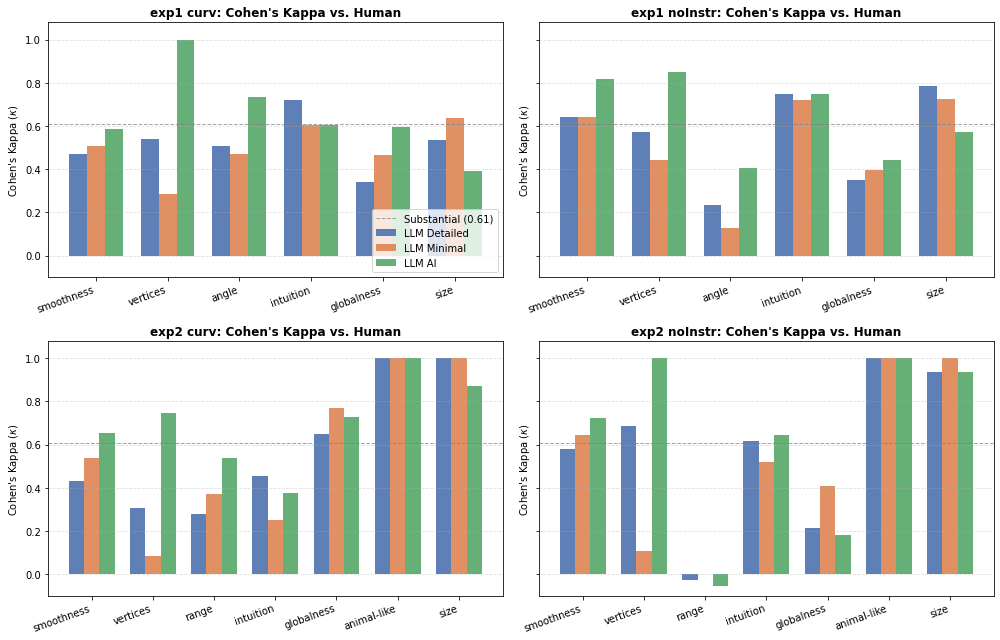

In [3]:
for exp in EXPERIMENTS:
    sub = metrics_df[metrics_df["Experiment"] == exp]
    feats = EXPERIMENT_FEATURES[exp]
    
    rows = []
    for f in feats:
        f_sub = sub[sub["Feature"] == f].set_index("LLM_Model")
        rows.append({
            "Feature": f,
            "Detailed Agr (%)": f"{f_sub.loc['detailed', 'Agreement_Pct']:.1f}%",
            "Detailed Kappa": round(f_sub.loc["detailed", "Kappa"], 3),
            "Minimal Agr (%)": f"{f_sub.loc['minimal', 'Agreement_Pct']:.1f}%",
            "Minimal Kappa": round(f_sub.loc["minimal", "Kappa"], 3),
            "AI Agr (%)": f"{f_sub.loc['ai', 'Agreement_Pct']:.1f}%",
            "AI Kappa": round(f_sub.loc["ai", "Kappa"], 3),
        })
    print(f"=== [{exp}] Agreement & Cohen's Kappa vs. Human ===")
    display(pd.DataFrame(rows).set_index("Feature"))

# Plot Cohen's Kappa vs Human across all 4 experiments
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
axes = axes.flatten()
colors = {"detailed": "#4C72B0", "minimal": "#DD8452", "ai": "#55A868"}

for idx, exp in enumerate(EXPERIMENTS):
    ax = axes[idx]
    sub = metrics_df[metrics_df["Experiment"] == exp]
    feats = EXPERIMENT_FEATURES[exp]
    x = np.arange(len(feats))
    width = 0.25
    
    for m_idx, m in enumerate(LLM_MODELS):
        m_vals = [sub[(sub["Feature"] == f) & (sub["LLM_Model"] == m)]["Kappa"].values[0] for f in feats]
        ax.bar(x + (m_idx - 1) * width, m_vals, width, label=MODEL_LABELS[m], color=colors[m], alpha=0.9)
        
    ax.axhline(0.61, color="gray", linestyle="--", linewidth=1, alpha=0.7, label="Substantial (0.61)" if idx == 0 else "")
    ax.set_title(f"{exp}: Cohen's Kappa vs. Human", fontsize=12, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(feats, rotation=20, ha="right", fontsize=10)
    ax.set_ylim(-0.1, 1.08)
    ax.set_ylabel("Cohen's Kappa ($\\kappa$)")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    if idx == 0:
        ax.legend(frameon=True, loc="lower right")

plt.tight_layout()
plt.show()


## 4. Feature Prevalence Comparison (Human vs. 3 LLMs)

Compares how frequently each feature is coded as `1` (present) by **Human** vs. **`detailed`**, **`minimal`**, and **`ai`** in each experiment.

=== [exp1 curv] Feature Prevalence: Count (% Coded 1) ===


,Human,LLM Detailed,LLM Minimal,LLM AI
Feature,,,,
smoothness,23 (65.7%),25 (71.4%),28 (80.0%),27 (77.1%)
vertices,19 (54.3%),19 (54.3%),10 (28.6%),19 (54.3%)
angle,12 (34.3%),7 (20.0%),10 (28.6%),10 (28.6%)
intuition,8 (22.9%),5 (14.3%),4 (11.4%),4 (11.4%)
globalness,7 (20.0%),6 (17.1%),7 (20.0%),13 (37.1%)
size,2 (5.7%),5 (14.3%),4 (11.4%),7 (20.0%)


=== [exp1 noInstr] Feature Prevalence: Count (% Coded 1) ===


,Human,LLM Detailed,LLM Minimal,LLM AI
Feature,,,,
smoothness,24 (66.7%),22 (61.1%),22 (61.1%),23 (63.9%)
vertices,28 (77.8%),21 (58.3%),18 (50.0%),26 (72.2%)
angle,16 (44.4%),9 (25.0%),11 (30.6%),8 (22.2%)
intuition,8 (22.2%),7 (19.4%),5 (13.9%),7 (19.4%)
globalness,13 (36.1%),14 (38.9%),13 (36.1%),24 (66.7%)
size,8 (22.2%),11 (30.6%),12 (33.3%),15 (41.7%)


=== [exp2 curv] Feature Prevalence: Count (% Coded 1) ===


,Human,LLM Detailed,LLM Minimal,LLM AI
Feature,,,,
smoothness,20 (55.6%),22 (61.1%),24 (66.7%),24 (66.7%)
vertices,8 (22.2%),9 (25.0%),19 (52.8%),7 (19.4%)
range,4 (11.1%),2 (5.6%),1 (2.8%),6 (16.7%)
intuition,6 (16.7%),2 (5.6%),1 (2.8%),3 (8.3%)
globalness,15 (41.7%),13 (36.1%),15 (41.7%),20 (55.6%)
animal-like,2 (5.6%),2 (5.6%),2 (5.6%),2 (5.6%)
size,4 (11.1%),4 (11.1%),4 (11.1%),5 (13.9%)


=== [exp2 noInstr] Feature Prevalence: Count (% Coded 1) ===


,Human,LLM Detailed,LLM Minimal,LLM AI
Feature,,,,
smoothness,28 (77.8%),29 (80.6%),30 (83.3%),31 (86.1%)
vertices,6 (16.7%),10 (27.8%),23 (63.9%),6 (16.7%)
range,1 (2.8%),1 (2.8%),0 (0.0%),12 (33.3%)
intuition,8 (22.2%),9 (25.0%),8 (22.2%),6 (16.7%)
globalness,16 (44.4%),16 (44.4%),8 (22.2%),21 (58.3%)
animal-like,3 (8.6%),3 (8.3%),3 (8.3%),3 (8.3%)
size,11 (30.6%),12 (33.3%),11 (30.6%),12 (33.3%)


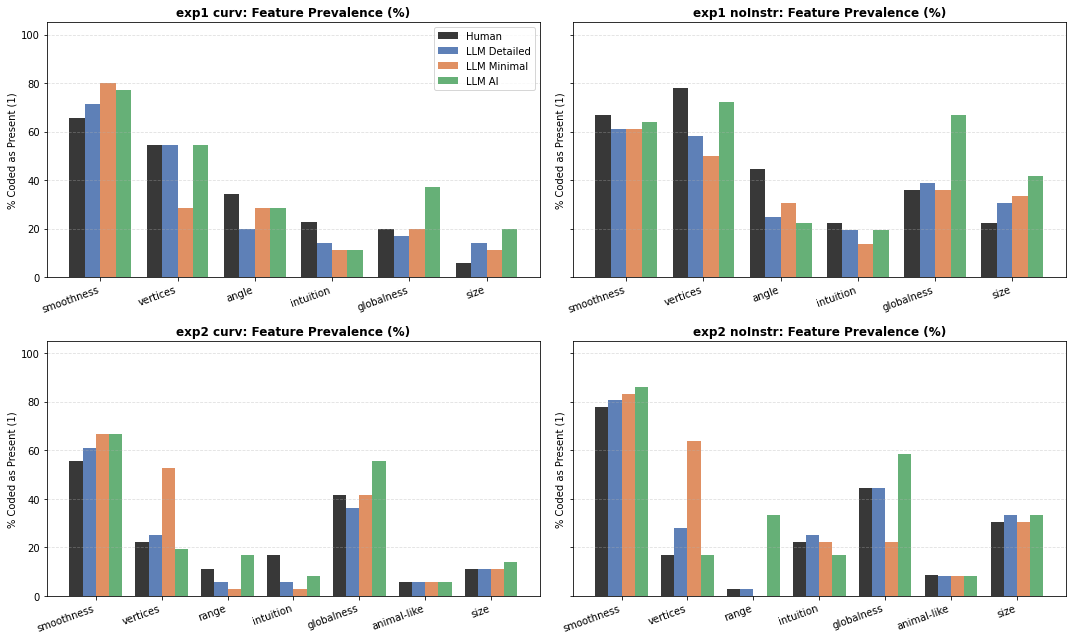

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharey=True)
axes = axes.flatten()
all_sources = ["human", "detailed", "minimal", "ai"]
bar_colors = {"human": "#222222", "detailed": "#4C72B0", "minimal": "#DD8452", "ai": "#55A868"}

for idx, exp in enumerate(EXPERIMENTS):
    merged = aligned_data[exp]
    feats = EXPERIMENT_FEATURES[exp]
    
    prev_rows = []
    for f in feats:
        row_dict = {"Feature": f}
        for src in all_sources:
            col = merged[f"{f}_{src}"].dropna().astype(int)
            cnt = int(col.sum())
            pct = col.mean() * 100
            row_dict[f"{MODEL_LABELS[src]}"] = f"{cnt} ({pct:.1f}%)"
            row_dict[f"_{src}_pct"] = pct
        prev_rows.append(row_dict)
        
    prev_df = pd.DataFrame(prev_rows)
    print(f"=== [{exp}] Feature Prevalence: Count (% Coded 1) ===")
    display(prev_df[["Feature"] + [MODEL_LABELS[s] for s in all_sources]].set_index("Feature"))
    
    # Plot bars
    ax = axes[idx]
    x = np.arange(len(feats))
    width = 0.2
    for s_idx, src in enumerate(all_sources):
        ax.bar(
            x + (s_idx - 1.5) * width,
            prev_df[f"_{src}_pct"],
            width,
            label=MODEL_LABELS[src],
            color=bar_colors[src],
            alpha=0.9,
        )
    ax.set_title(f"{exp}: Feature Prevalence (%)", fontsize=12, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(feats, rotation=20, ha="right", fontsize=10)
    ax.set_ylim(0, 105)
    ax.set_ylabel("% Coded as Present (1)")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    if idx == 0:
        ax.legend(frameon=True)

plt.tight_layout()
plt.show()


## 5. Confusion Matrices vs. Human (Select Experiment)

Change `SELECTED_EXPERIMENT` below (`'exp1 curv'`, `'exp1 noInstr'`, `'exp2 curv'`, or `'exp2 noInstr'`) to inspect the $2 \times 2$ confusion matrices of **Human (Rows)** vs. each of the **3 LLM Models (Columns)** for every feature.

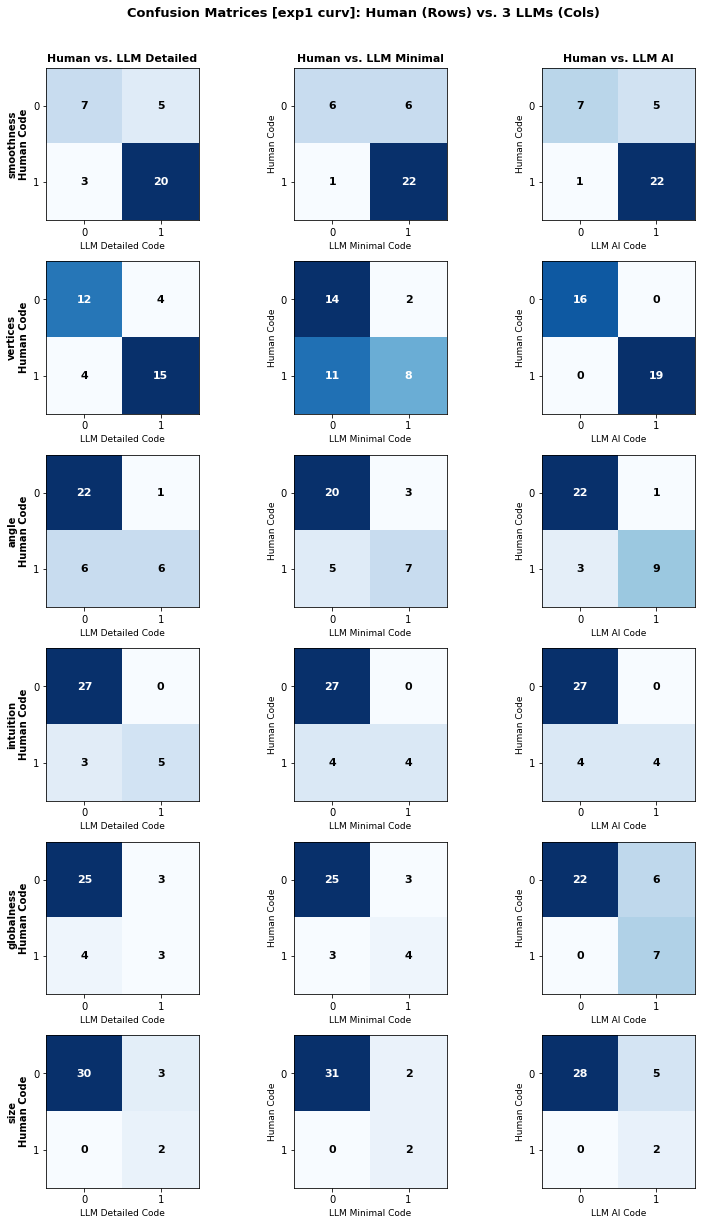

In [5]:
# Choose experiment to visualize confusion matrices ('exp1 curv', 'exp1 noInstr', 'exp2 curv', 'exp2 noInstr')
SELECTED_EXPERIMENT = "exp1 curv"

merged_sel = aligned_data[SELECTED_EXPERIMENT]
feats_sel = EXPERIMENT_FEATURES[SELECTED_EXPERIMENT]

fig, axes = plt.subplots(len(feats_sel), 3, figsize=(11, 2.8 * len(feats_sel)))

for r_idx, f in enumerate(feats_sel):
    for c_idx, m in enumerate(LLM_MODELS):
        ax = axes[r_idx, c_idx]
        sub = merged_sel[[f"{f}_human", f"{f}_{m}"]].dropna()
        vh = sub[f"{f}_human"].astype(int)
        vm = sub[f"{f}_{m}"].astype(int)
        
        cm = confusion_matrix(vh, vm, labels=[0, 1])
        ax.imshow(cm, cmap="Blues", interpolation="nearest")
        
        if r_idx == 0:
            ax.set_title(f"Human vs. {MODEL_LABELS[m]}", fontsize=11, fontweight="bold")
        if c_idx == 0:
            ax.set_ylabel(f"{f}\nHuman Code", fontsize=10, fontweight="bold")
        else:
            ax.set_ylabel("Human Code", fontsize=9)
            
        ax.set_xlabel(f"{MODEL_LABELS[m]} Code", fontsize=9)
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(["0", "1"])
        ax.set_yticklabels(["0", "1"])
        
        thresh = cm.max() / 2.0
        for i in range(2):
            for j in range(2):
                val = cm[i, j]
                ax.text(
                    j, i, f"{val}",
                    ha="center", va="center",
                    color="white" if val > thresh else "black",
                    fontsize=11, fontweight="bold"
                )

plt.suptitle(f"Confusion Matrices [{SELECTED_EXPERIMENT}]: Human (Rows) vs. 3 LLMs (Cols)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


## 6. Participant-Level Discrepancy Breakdown & Multi-Sheet Export

Identifies all participant responses where any of the 3 LLM models disagreed with the **Human Annotation**, and saves a complete multi-sheet Excel report (`Curvature_Open_Answers_Human_vs_LLMs_Comparison.xlsx`) inside `Open_Answers/`.

In [6]:
discrepancy_sheets = {}
agreement_overview = []

for exp in EXPERIMENTS:
    merged = aligned_data[exp]
    feats = EXPERIMENT_FEATURES[exp]
    total_subj = len(merged)
    
    # Perfect match counts per model across all features in the experiment
    perfect_counts = {}
    for m in LLM_MODELS:
        mismatches = pd.Series(0, index=merged.index)
        for f in feats:
            v_h = merged[f"{f}_human"]
            v_m = merged[f"{f}_{m}"]
            both_valid = v_h.notna() & v_m.notna()
            mismatches += (both_valid & (v_h != v_m)).astype(int)
        perfect_counts[m] = int((mismatches == 0).sum())
        
    agreement_overview.append({
        "Experiment": exp,
        "Total Participants": total_subj,
        "100% Match (Detailed vs Human)": f"{perfect_counts['detailed']}/{total_subj} ({perfect_counts['detailed']/total_subj:.1%})",
        "100% Match (Minimal vs Human)": f"{perfect_counts['minimal']}/{total_subj} ({perfect_counts['minimal']/total_subj:.1%})",
        "100% Match (AI vs Human)": f"{perfect_counts['ai']}/{total_subj} ({perfect_counts['ai']/total_subj:.1%})",
    })
    
    # Build participant-level discrepancy table
    rows = []
    for _, row in merged.iterrows():
        diff_items = []
        for f in feats:
            vh = row[f"{f}_human"]
            vd = row[f"{f}_detailed"]
            vm = row[f"{f}_minimal"]
            va = row[f"{f}_ai"]
            if pd.isna(vh):
                continue
            if any(pd.notna(v) and v != vh for v in [vd, vm, va]):
                diff_items.append(f"{f}: H={vh} (Det={vd}, Min={vm}, AI={va})")
        if diff_items:
            rows.append({
                "subj_id": row["subj_id"],
                "discrepancies (H=Human, Det=Detailed, Min=Minimal, AI=AI)": " | ".join(diff_items),
                "response_text": row["response_text"],
                "rationale_detailed": row.get("rationale_detailed", ""),
                "rationale_minimal": row.get("rationale_minimal", ""),
            })
    discrepancy_sheets[exp] = pd.DataFrame(rows)

print("=== Participants with 100% Agreement Across All Experiment Features ===")
display(pd.DataFrame(agreement_overview))

# Show discrepancy preview for SELECTED_EXPERIMENT
print(f"\n=== Discrepancies in [{SELECTED_EXPERIMENT}] ({len(discrepancy_sheets[SELECTED_EXPERIMENT])} participants with >=1 difference) ===")
pd.set_option("display.max_colwidth", None)
display(discrepancy_sheets[SELECTED_EXPERIMENT].head(15))

# Export comprehensive comparison & discrepancies workbook to Open_Answers/
export_path = os.path.join(BASE_DIR, "Curvature_Open_Answers_Human_vs_LLMs_Comparison.xlsx")
with pd.ExcelWriter(export_path, engine="openpyxl") as writer:
    overall_summary.to_excel(writer, sheet_name="Overall_Summary", index=False)
    exp_summary.to_excel(writer, sheet_name="Experiment_Summary", index=False)
    metrics_df.to_excel(writer, sheet_name="All_Feature_Metrics", index=False)
    for exp, d_df in discrepancy_sheets.items():
        d_df.to_excel(writer, sheet_name=f"Diff_{exp}", index=False)

print(f"\nSaved full comparison workbook to: {export_path}")


=== Participants with 100% Agreement Across All Experiment Features ===


,Experiment,Total Participants,100% Match (Detailed vs Human),100% Match (Minimal vs Human),100% Match (AI vs Human)
0,exp1 curv,35,13/35 (37.1%),12/35 (34.3%),15/35 (42.9%)
1,exp1 noInstr,36,10/36 (27.8%),9/36 (25.0%),14/36 (38.9%)
2,exp2 curv,36,16/36 (44.4%),12/36 (33.3%),20/36 (55.6%)
3,exp2 noInstr,36,12/36 (33.3%),8/36 (22.2%),13/36 (36.1%)



=== Discrepancies in [exp1 curv] (31 participants with >=1 difference) ===


,subj_id,"discrepancies (H=Human, Det=Detailed, Min=Minimal, AI=AI)",response_text,rationale_detailed,rationale_minimal
0,66310,"vertices: H=1 (Det=0, Min=0, AI=1) | angle: H=1 (Det=0, Min=0, AI=1) | intuition: H=1 (Det=0, Min=0, AI=0)","I looked at what stood out to me first. I paid attention to the roundness of the shape, the number of curves, and the size or direction of the curve.","Focus on roundness, curve count, and size/direction shows smoothness and size but no angle or intuition.","Focus on roundness, curve count, and size/direction indicates smoothness and size criteria."
1,66349,"vertices: H=1 (Det=1, Min=0, AI=1)","I generally looked at the overall shape of the line like how many bumps it had, where it started and ended, was it more or less curvy. A lot of decisions were instinctual because there was multiple valid “odd ones” so in those cases I chose one by instinct. The most difficult choices were when there was an ascending pattern which made the decisions difficult. I didn’t”t differentiate very strongly on if the tip of the bump was sharp or round but rather the number of bumps and the steepness or angle of the bump","Cites overall shape, bump count, steepness, and instinct, covering smoothness, vertices, angle, intuition, and globalness.","Cites overall shape, bump count, instinct, and bump angle, covering multiple features."
2,66403,"vertices: H=1 (Det=0, Min=0, AI=1)","I really had three criteria and picked based off of which ever shape most distinctly fit any of the three. Generally I pocked a shape if it seemed to be doing a different thing from the others, i.e. moving/sloping/angling in another direction from the others. Or else If one had noticeably less/more curves than the others I picked that. Lastly if the shape of its angles were noticeably more hard or soft from the others. I compared the three shapes and picked accordingly.","References direction, curve count, and angle hardness, indicating smoothness and angle but no size or intuition.","Uses direction, curve count, and angle hardness to select the odd shape."
3,66406,"vertices: H=1 (Det=1, Min=0, AI=1)",The number of bumps and how straight/curved an object was.,"Mentions bump count and curvature, covering vertices and smoothness.",Focuses on bump count and curvature versus straightness.
4,66412,"smoothness: H=0 (Det=1, Min=1, AI=1) | vertices: H=1 (Det=1, Min=0, AI=1) | angle: H=1 (Det=0, Min=0, AI=0)","counting the number of lumps, the shapes of the curves and bends","Counts lumps and notes curve shapes, indicating vertices and smoothness.","Emphasizes lump count and curve/bend shapes, indicating smoothness."
5,66766,"globalness: H=1 (Det=0, Min=0, AI=1) | size: H=0 (Det=1, Min=1, AI=1)","I tried to see how manu ""bumps"" there were or how much the shape took up space of the box. Some of them were confusing, but others were really obvious.",Looks at number of bumps and overall occupied space to decide.,Looks at number of bumps (vertices) and overall size of shape within the box.
6,66799,"globalness: H=0 (Det=0, Min=0, AI=1)","I made some priorities: 1) Curvature difference, either zigzag or curved. 2) If they are the same type of curvature, checking if they are part of each other, like if there is part of one cut and it is shown. 3) If the same type of curvature, and the same number of zigzags, smoother or steeper one.","Prioritizes curvature type, then count of zigzags, finally smoothness versus steepness.","Prioritizes curvature type, then part relations, then counts of zigzags and smoothness/steepness."
7,66847,"vertices: H=0 (Det=1, Min=1, AI=0) | angle: H=1 (Det=0, Min=0, AI=1) | globalness: H=0 (Det=1, Min=0, AI=1) | size: H=0 (Det=0, Min=0, AI=1)",When I chose the odd one out I tended to chose the one that was either the only corner or the only curve. I also looked at the depth and positioning and if they were similar I would pic the other as the odd one out.,"Selects based on unique corner or curve, also considers depth and position."


Saved full comparison workbook to: ./Curvature_Open_Answers_Human_vs_LLMs_Comparison.xlsx
